# Forecasting 60-Second Trade-Price Returns for China A-Share Large Caps

**IEOR 4511 Capstone: High-Frequency Forecasting, 1-minute horizon, level 2 tick data**

This notebook forecasts the signed 60-second return of the traded price, in basis points, for 50 large China A-share stocks listed in Shanghai and Shenzhen. The input is the course-provided level 2 tick-by-tick trade feed for 2025, aggregated into 5-second trade bars. The modelling pipeline (multi-horizon pretraining, 60 s fine-tuning, per-stock heads, seed ensembles) is the same one used for the US NBBO study, so the two markets can be compared on one method.

| | |
|---|---|
| **Target** | 60 s log return between forward 15 s VWAPs, starting just after the forecast time (bps); direction class plus standardized magnitude |
| **Data** | Level 2 tick-by-tick trades (`l2tick_2025MM.csv.gz`): price, size, aggressor side, order sequence numbers |
| **Universe** | 50 large A-shares (Shanghai and Shenzhen main boards, ChiNext, STAR) |
| **Sample** | January to June 2025, continuous auction only (09:30 to 11:30, 13:00 to 14:57) |
| **Splits** | Train: Jan to Apr 2025 · Validation: May 2025 · Locked test: June 2025 |
| **Models** | GRU, LSTM, causal TCN with stock embeddings and per-horizon output heads |
| **Benchmark** | Zero-return forecast |

### Notebook outline
0. Environment setup
1. Configuration
2. Tick data to 5-second trade bars
3. Session grid and data quality
4. Features and multi-horizon labels
5. Integrity and lookahead tests
6. Session-safe sequence construction
7. Model architecture
8. Training: multi-horizon pretraining, 60 s fine-tuning, per-stock heads
9. Validation analysis and seed ensembles
10. Saved artifacts and checkpoint verification
11. Locked final test

> **Scope.** The feed contains executed trades only, with no bid or ask quotes, so there is no midquote, spread or displayed depth. Results describe predictability of traded prices in this sample and are not evidence of a tradeable strategy: A-shares settle T+1 and short selling is restricted.

## Methodology

**Label: forward-start VWAP.** Without quotes the natural price is the last trade, which jumps between bid and ask as buyers and sellers alternate (bid-ask bounce). A model can predict that bounce mechanically without learning anything tradeable. The reference price is a **15-second VWAP** (three 5 s bars), which averages buyer- and seller-initiated prints, and the label **starts after the forecast time**: it is the log change from the VWAP of (t, t+15 s] to the VWAP of (t+60 s, t+75 s]. Its starting price contains no trade the model has seen, and it is roughly the price a trader acting at t could obtain.

A first run used the trailing VWAP at t as the starting price. It reached a validation IC of 0.30, but almost all of it was mechanical: the trailing VWAP still carries bounce from the latest prints, and that error reverts. A single feature (last trade versus VWAP) had IC 0.13 under that label and 0.00 under the forward-start label, and a linear model fit on January to April fell from 0.15 to 0.06 (`oos/label_and_linear.py`). The comparison is kept in the results folder.

**Aggressor side.** Shanghai reports the aggressor (`bsflag` B or S). Shenzhen does not, so the aggressor is taken to be the order that arrived later, i.e. the larger of the bid and offer order sequence numbers. Order flow imbalance is built from these signed volumes.

**Sessions.** Only the continuous auction is used. Opening (09:25) and closing (14:57 to 15:00) call-auction prints are dropped. Morning and afternoon are treated as separate segments: no rolling window, input sequence or label crosses the lunch break or the overnight gap.

**Problem framing.** As in the US study, the model has two linked outputs:
- **Direction:** down, flat, up, with a ±5 bps dead zone, trained with class-weighted cross-entropy. The dead zone was set from January (training) labels so that the three classes are roughly balanced; 60 s moves here are about five times larger than for US large caps because the 1-cent tick is 3 to 11 bps of price.
- **Magnitude:** the return divided by each stock's training-window standard deviation, trained with a Huber loss weighted by λ = 0.2.

A 16-dimensional **stock embedding** lets one pooled network represent 50 stocks.

**Training schedule.** Multi-horizon pretraining on 15, 30, 60 and 120 s heads (weights 0.5, 0.75, 1.0, 0.5), then 60 s fine-tuning with the backbone frozen, then per-stock 60 s heads. Three architectures, three seeds each, averaged into seed ensembles.

**Features.** 27 causal inputs on the 5 s grid:

| Group | Features |
|---|---|
| Price and volatility | 5, 15, 60 and 120 s VWAP returns; 1 and 5 min realized volatility and their ratio; 1 min high-low range; last trade versus VWAP; tick size in bps |
| Order flow | Signed volume imbalance over 5 s, 30 s, 1 min and 5 min; signed trade-count imbalance over 1 min |
| Activity | Log volume and trade count per bar; 1 min log volume; 1 min average trade size; trade intensity ratio (1 min versus 5 min); time since last trade; stock-relative 1 min volume z-score |
| Context | Distance to the daily up and down price limits (±10%, or ±20% for ChiNext and STAR); time of day (sine and cosine); afternoon flag |

**Evaluation.** On May 2025 only, with the team repository's definitions where they overlap: Spearman IC with a per-session t-statistic, balanced accuracy, plus Pearson IC, directional accuracy on confident predictions (|P(up) - P(down)| > 0.1), MAE against the zero forecast, per-stock tables, a daily sign test, and a tick-size check (does per-stock IC simply rise with tick size, which would point to residual bounce?).

## 0. Environment setup
Installs Polars and Parquet support, then imports the scientific stack and reports GPU availability.

In [1]:
%pip -q install polars pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, json, math, time, copy, random, warnings
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display
import polars as pl

pd.set_option("display.max_columns", 40)
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())

PyTorch: 2.9.1+cu129 | CUDA available: True


## 1. Configuration

All experiment settings live in this cell. `STORAGE='drive'` keeps raw files, the bar cache and results on Google Drive (Colab); `STORAGE='local'` uses `./cn_l2_60s_research` on the machine's disk. Raw files are expected in `RAW_DIR` (override with the `L2_RAW_DIR` environment variable). Once the monthly bar cache exists, the raw files are no longer needed.

In [3]:
# ==== Experiment configuration ====
STORAGE = "local"
DATA_MODE = "l2_trades"
UNIVERSE_SOURCE = "Course-provided China A-share top-50 level 2 tick-by-tick trades, 2025"
MONTHS = ["202501", "202502", "202503", "202504", "202505", "202506"]
RAW_FILE_PATTERN = "l2tick_{month}.csv.gz"
MAX_TICKERS = None                  # None keeps every stock in the files

# ---- Universe hygiene and target definition ----
EXCLUDE_TICKERS = []
QUARANTINE_TICKERS = []
DEAD_ZONE_BPS = 5.0                 # set on January (training) labels: roughly balanced classes
LAMBDA_MAGNITUDE = 0.2
TARGET_STANDARDIZE = True
EMBED_DIM = 16
N_CLASSES = 3

# ---- Multi-horizon pretraining and fine-tuning ----
PRETRAIN_HORIZONS_S = [15, 30, 60, 120]        # horizons with their own heads in phase 1
PRIMARY_HORIZON_S   = 60                        # evaluation horizon
HORIZON_LOSS_WEIGHTS = {15: 0.5, 30: 0.75, 60: 1.0, 120: 0.5}
PRETRAIN_EPOCHS = 20
FINETUNE_EPOCHS = 10
FINETUNE_LR = 1e-4
PER_TICKER_EPOCHS = 8
PER_TICKER_LR = 5e-5
RUN_PER_TICKER = True

START_DATE = "2025-01-01"
END_DATE = "2025-06-30"
TRAIN_END = "2025-04-30"
VAL_END = "2025-05-31"
RUN_FINAL_TEST = os.environ.get("RUN_FINAL_TEST") == "1"   # the batch runner sets this once the configuration is frozen
GRID_SECONDS = 5
HORIZON_SECONDS = PRIMARY_HORIZON_S
LOOKBACK_STEPS = 60                 # 5 minutes of 5 s bars
STRIDE_STEPS = 24                   # one window every 2 minutes
MAX_TRADE_AGE_SECONDS = 30.0        # a bar is usable if the stock traded in the last 30 s
FEATURE_SET = "all"
MODELS = ["GRU", "LSTM", "TCN"]
SEEDS = [42, 123, 7]
HIDDEN_DIM = 64
MAX_EPOCHS = PRETRAIN_EPOCHS
PATIENCE = 6
BATCH_SIZE = 512
LR = 3e-4
WEIGHT_DECAY = 1e-4
LOSS_NAME = "multihead_composite"

if os.environ.get("NOTEBOOK_SMOKE") == "1":      # quick end-to-end check on real data
    MONTHS = ["202501", "202502"]; MAX_TICKERS = 8
    TRAIN_END = "2025-01-17"; VAL_END = "2025-01-27"
    MODELS = ["GRU", "TCN"]; SEEDS = [42]
    PRETRAIN_EPOCHS = 2; FINETUNE_EPOCHS = 1; PER_TICKER_EPOCHS = 1
    PATIENCE = 2; HIDDEN_DIM = 24; MAX_EPOCHS = PRETRAIN_EPOCHS

SEED = 42
assert HORIZON_SECONDS % GRID_SECONDS == 0
assert PRIMARY_HORIZON_S in PRETRAIN_HORIZONS_S
assert all(h % GRID_SECONDS == 0 for h in PRETRAIN_HORIZONS_S)
assert all(h in HORIZON_LOSS_WEIGHTS for h in PRETRAIN_HORIZONS_S)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu": torch.set_num_threads(min(4, torch.get_num_threads()))
if STORAGE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/cn_l2_60s_research")
else:
    BASE = Path("cn_l2_60s_research")
RAW_DIR = Path(os.environ.get("L2_RAW_DIR", BASE / "raw"))
BAR_CACHE = BASE / "trade_bars_5s"
RESULTS_DIR = BASE / "results_60s_multihorizon"
for path in [BAR_CACHE, RESULTS_DIR]: path.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE, "| months:", MONTHS)
print("Pretrain horizons:", PRETRAIN_HORIZONS_S, "| primary:", PRIMARY_HORIZON_S)
print("Pretrain epochs:", PRETRAIN_EPOCHS, "| fine-tune:", FINETUNE_EPOCHS,
      "| per-ticker:", PER_TICKER_EPOCHS if RUN_PER_TICKER else "OFF")
print("Models:", MODELS, "| seeds:", SEEDS, "| results ->", RESULTS_DIR)

Device: cuda | months: ['202501', '202502', '202503', '202504', '202505', '202506']
Pretrain horizons: [15, 30, 60, 120] | primary: 60
Pretrain epochs: 20 | fine-tune: 10 | per-ticker: 8
Models: ['GRU', 'LSTM', 'TCN'] | seeds: [42, 123, 7] | results -> cn_l2_60s_research/results_60s_multihorizon


## 2. Tick data to 5-second trade bars

Each monthly file holds every executed trade for the 50 stocks. Trades are aggregated into 5-second bars per stock and day. A bar labelled *t* holds trades in [*t* - 5 s, *t*), so everything in it was known at its timestamp. Each bar keeps first, last, high and low price, volume, turnover, trade count, and buyer- and seller-initiated volume and counts.

Only continuous-auction trades are kept. Bars are cached as one Parquet file per month, so the raw files are read once; rerunning the cell reuses the cache.

In [4]:
import polars as pl

RAW_SCHEMA = {
    "date": pl.Utf8, "sid": pl.Utf8, "exch": pl.Utf8, "time": pl.Utf8,
    "price": pl.Float64, "qty": pl.Float64, "amount": pl.Float64, "bsflag": pl.Utf8,
    "buyno": pl.Int64, "sellno": pl.Int64, "bidseq": pl.Int64, "offerseq": pl.Int64,
    "channel": pl.Int64, "seqno": pl.Int64,
}
# Continuous-auction windows in seconds after midnight, [start, end). Call auctions
# (09:15-09:25 open, 14:57-15:00 close) and the 11:30-13:00 lunch break are excluded.
MORNING = (9 * 3600 + 30 * 60, 11 * 3600 + 30 * 60)
AFTERNOON = (13 * 3600, 14 * 3600 + 57 * 60)


def trade_side():
    """+1 buyer-initiated, -1 seller-initiated, 0 unknown.

    Shanghai reports the aggressor in `bsflag`. Shenzhen does not, so the aggressor is the
    order that arrived later, i.e. the larger of the bid and offer order sequence numbers.
    """
    sh = (pl.when(pl.col("bsflag") == "B").then(1)
            .when(pl.col("bsflag") == "S").then(-1).otherwise(0))
    sz = (pl.when(pl.col("bidseq") > pl.col("offerseq")).then(1)
            .when(pl.col("bidseq") < pl.col("offerseq")).then(-1).otherwise(0))
    return pl.when(pl.col("exch") == "SH").then(sh).otherwise(sz).cast(pl.Int8)


def build_month_bars(raw_path, out_path):
    """Aggregate one month of tick-by-tick trades into 5 s trade bars.

    A bar labelled `bucket` (seconds after midnight) holds trades in [bucket - 5, bucket),
    so everything in it was known at the bar's timestamp.
    """
    hms = pl.col("time").str.split(":")
    secs = (hms.list.get(0).cast(pl.Float64) * 3600 + hms.list.get(1).cast(pl.Float64) * 60
            + hms.list.get(2).cast(pl.Float64))
    trades = (
        pl.read_csv(raw_path, schema_overrides=RAW_SCHEMA)
        .with_columns(secs.alias("secs"), trade_side().alias("side"),
                      (pl.col("sid") + "." + pl.col("exch")).alias("ticker"))
        .filter((pl.col("price") > 0) & (pl.col("qty") > 0)
                & (((pl.col("secs") >= MORNING[0]) & (pl.col("secs") < MORNING[1]))
                   | ((pl.col("secs") >= AFTERNOON[0]) & (pl.col("secs") < AFTERNOON[1]))))
        .with_columns(((pl.col("secs") // GRID_SECONDS) * GRID_SECONDS + GRID_SECONDS)
                      .cast(pl.Int32).alias("bucket"))
    )
    buy = pl.col("side") == 1
    sell = pl.col("side") == -1
    order = ["secs", "seqno"]
    bars = (
        trades.group_by(["ticker", "date", "bucket"])
        .agg(pl.col("price").sort_by(order).first().alias("first"),
             pl.col("price").sort_by(order).last().alias("last"),
             pl.col("price").max().alias("high"), pl.col("price").min().alias("low"),
             pl.len().cast(pl.Int32).alias("n_trades"),
             pl.col("qty").sum().alias("volume"), pl.col("amount").sum().alias("amount"),
             pl.col("qty").filter(buy).sum().alias("buy_volume"),
             pl.col("qty").filter(sell).sum().alias("sell_volume"),
             buy.sum().cast(pl.Int32).alias("buy_trades"),
             sell.sum().cast(pl.Int32).alias("sell_trades"),
             (pl.col("side") == 0).sum().cast(pl.Int32).alias("unsigned_trades"))
        .sort(["ticker", "date", "bucket"])
    )
    bars.write_parquet(out_path)
    return bars.height, trades.height


for month in MONTHS:
    out = BAR_CACHE / f"bars_{month}.parquet"
    if out.exists():
        print(f"{month}: cached bars found"); continue
    raw = RAW_DIR / RAW_FILE_PATTERN.format(month=month)
    if not raw.exists():
        raise FileNotFoundError(f"Missing {raw}. Put the level 2 files in {RAW_DIR} or set L2_RAW_DIR.")
    started = time.perf_counter()
    n_bars, n_trades = build_month_bars(raw, out)
    print(f"{month}: {n_trades:,} trades -> {n_bars:,} bars in {time.perf_counter() - started:.0f}s")

bars = pl.concat([pl.read_parquet(BAR_CACHE / f"bars_{m}.parquet") for m in MONTHS])
SYMBOLS = sorted(bars["ticker"].unique().to_list())
if MAX_TICKERS:
    SYMBOLS = SYMBOLS[:MAX_TICKERS]
    bars = bars.filter(pl.col("ticker").is_in(SYMBOLS))
if EXCLUDE_TICKERS:
    SYMBOLS = [s for s in SYMBOLS if s not in EXCLUDE_TICKERS]
    bars = bars.filter(pl.col("ticker").is_in(SYMBOLS))
requested_dates = sorted(bars["date"].unique().to_list())
totals = bars.select(pl.col("n_trades").sum(), pl.col("buy_trades").sum(),
                     pl.col("sell_trades").sum(), pl.col("unsigned_trades").sum()).row(0)
print(f"Stocks: {len(SYMBOLS)} | sessions: {len(requested_dates)} "
      f"({requested_dates[0]} to {requested_dates[-1]}) | bars with trades: {bars.height:,}")
print(f"Trades: {totals[0]:,} | buyer-initiated {totals[1]/totals[0]:.1%} | "
      f"seller-initiated {totals[2]/totals[0]:.1%} | unsigned {totals[3]/totals[0]:.2%}")

202501: cached bars found
202502: cached bars found
202503: cached bars found
202504: cached bars found
202505: cached bars found
202506: cached bars found


Stocks: 50 | sessions: 117 (20250102 to 20250630) | bars with trades: 14,653,144
Trades: 300,306,886 | buyer-initiated 48.4% | seller-initiated 51.6% | unsigned 0.00%


## 3. Session grid and data quality

Every stock-day gets the full grid of 2,844 continuous-auction bars (1,440 in the morning, 1,404 in the afternoon). Bars without trades keep zero volume and carry the last price forward; they are counted, not hidden. A bar is **usable** when the stock traded within the last `MAX_TRADE_AGE_SECONDS`.

In [5]:

SEGMENT_SECONDS = (MORNING[1] - MORNING[0]) + (AFTERNOON[1] - AFTERNOON[0])   # 14,220 s of continuous trading
DAY_KEYS = ["ticker", "date"]
SEG_KEYS = ["ticker", "date", "segment"]
EPS = 1e-12
LABEL_DELAY_STEPS = 3     # labels start one VWAP window (15 s) after the forecast time

TRADE_FEATURES = [
    "ret_5s_bps", "ret_15s_bps", "ret_60s_bps", "ret_120s_bps",
    "vol_1m_bps", "vol_5m_bps", "volatility_regime_ratio", "range_1m_bps",
    "last_vs_vwap_bps", "tick_bps",
]
FLOW_FEATURES = [
    "flow_imbalance_5s", "flow_imbalance_30s", "flow_imbalance_1m", "flow_imbalance_5m",
    "count_imbalance_1m",
]
ACTIVITY_FEATURES = [
    "log_volume", "log_trades", "log_volume_1m", "log_avg_trade_size_1m",
    "trade_intensity_ratio", "log_secs_since_trade",
]
CONTEXT_FEATURES = ["dist_limit_up_pct", "dist_limit_down_pct", "tod_sin", "tod_cos", "afternoon"]
STOCK_RELATIVE = ["volume_1m_stock_z"]   # added later with train-window statistics


def full_grid(bars):
    """Every 5 s bar of every continuous session, with empty bars where nothing traded."""
    buckets = (list(range(MORNING[0] + GRID_SECONDS, MORNING[1] + 1, GRID_SECONDS))
               + list(range(AFTERNOON[0] + GRID_SECONDS, AFTERNOON[1] + 1, GRID_SECONDS)))
    grid = (bars.select(DAY_KEYS).unique()
            .join(pl.DataFrame({"bucket": buckets}, schema={"bucket": pl.Int32}), how="cross"))
    counts = ["n_trades", "volume", "amount", "buy_volume", "sell_volume",
              "buy_trades", "sell_trades", "unsigned_trades"]
    clock = (pl.when(pl.col("bucket") <= MORNING[1])
               .then(pl.col("bucket") - MORNING[0])
               .otherwise(pl.col("bucket") - AFTERNOON[0] + (MORNING[1] - MORNING[0])))
    return (grid.join(bars, on=DAY_KEYS + ["bucket"], how="left")
            .with_columns(pl.col(counts).fill_null(0),
                          (pl.col("bucket") > MORNING[1]).cast(pl.Int8).alias("segment"),
                          clock.cast(pl.Int32).alias("clock"))
            .sort(DAY_KEYS + ["bucket"]))


grid = full_grid(bars)
per_day = grid.group_by(DAY_KEYS).len()
assert per_day["len"].min() == per_day["len"].max() == 2844, "incomplete session grid"
quality = (grid.group_by(DAY_KEYS)
           .agg((pl.col("n_trades") > 0).mean().alias("traded_bar_share"),
                pl.col("n_trades").sum().alias("trades"),
                pl.col("volume").sum().alias("volume"))
           .sort(DAY_KEYS).to_pandas())
print(f"Grid: {grid.height:,} bars = {per_day.height:,} stock-days x 2,844")
print("Share of 5 s bars with at least one trade, by stock (lowest five):")
display(quality.groupby("ticker").traded_bar_share.mean().sort_values().head().round(3))

Grid: 16,600,428 bars = 5,837 stock-days x 2,844
Share of 5 s bars with at least one trade, by stock (lowest five):


ticker
688027.SH    0.570
300779.SZ    0.642
688235.SH    0.675
688608.SH    0.716
688116.SH    0.750
Name: traded_bar_share, dtype: float64

## 4. Features and multi-horizon labels

Rolling statistics use only current and past bars and restart at each segment. Forward labels are computed for every pretraining horizon (15, 30, 60, 120 s), start 15 s after the forecast time, and are valid only when the stock traded recently at the forecast time and at both ends of the label, all within the same segment. The stock-relative volume z-score uses training-window statistics only. Feature subsets (`trade`, `flow`, `activity`, `all`) are available for ablation through `FEATURE_SET`.

In [6]:
def add_features_labels(grid, horizons, max_trade_age_s):
    """Causal trade features and forward VWAP-to-VWAP labels on the full 5 s grid.

    Rolling windows restart at each session segment (morning, afternoon), so nothing
    crosses the lunch break or the overnight gap. The reference price is a 15 s VWAP,
    which averages buyer- and seller-initiated prints. The label runs from the VWAP of
    the 15 s right after the forecast time, (t, t+15], to the VWAP of (t+h, t+h+15], so
    its starting price contains no trade the features have seen. A label that starts
    from the trailing VWAP at t is largely predictable from the bounce already inside
    that VWAP, which is not something a trader acting at t can capture.
    """
    seg = SEG_KEYS
    roll = lambda e, w, op: getattr(e, op)(w).over(seg)
    f = grid.with_columns(
        pl.col("last").forward_fill().over(DAY_KEYS).alias("last_ff"),
        pl.when(pl.col("n_trades") > 0).then(pl.col("clock")).otherwise(None)
          .forward_fill().over(DAY_KEYS).alias("_last_trade_clock"),
        (roll(pl.col("amount"), 3, "rolling_sum")
         / roll(pl.col("volume"), 3, "rolling_sum")).alias("_vwap15"),
    ).with_columns(
        pl.when(pl.col("_vwap15").is_finite()).then(pl.col("_vwap15")).otherwise(None)
          .forward_fill().over(seg).alias("px"),
        (pl.col("clock") - pl.col("_last_trade_clock")).cast(pl.Float64).alias("secs_since_trade"),
    ).with_columns(
        (pl.col("px").is_not_null() & (pl.col("secs_since_trade") <= max_trade_age_s))
          .fill_null(False).alias("usable"),
        pl.col("px").log().alias("_lpx"),
    )
    signed = pl.col("buy_volume") - pl.col("sell_volume")
    total = pl.col("buy_volume") + pl.col("sell_volume")
    imb = lambda w: (roll(signed, w, "rolling_sum") / (roll(total, w, "rolling_sum") + EPS))
    f = f.with_columns(
        *[(1e4 * (pl.col("_lpx") - pl.col("_lpx").shift(k).over(seg))).alias(f"ret_{5*k}s_bps")
          for k in (1, 3, 12, 24)],
        (signed / (total + EPS)).alias("flow_imbalance_5s"),
        imb(6).alias("flow_imbalance_30s"), imb(12).alias("flow_imbalance_1m"),
        imb(60).alias("flow_imbalance_5m"),
        (roll(pl.col("buy_trades") - pl.col("sell_trades"), 12, "rolling_sum")
         / (roll(pl.col("buy_trades") + pl.col("sell_trades"), 12, "rolling_sum") + EPS))
          .alias("count_imbalance_1m"),
        pl.col("volume").log1p().alias("log_volume"),
        pl.col("n_trades").cast(pl.Float64).log1p().alias("log_trades"),
        roll(pl.col("volume"), 12, "rolling_sum").alias("_vol12"),
        roll(pl.col("n_trades").cast(pl.Float64), 12, "rolling_sum").alias("_n12"),
        roll(pl.col("n_trades").cast(pl.Float64), 60, "rolling_sum").alias("_n60"),
        (1e4 * (roll(pl.coalesce("high", "last_ff"), 12, "rolling_max")
                - roll(pl.coalesce("low", "last_ff"), 12, "rolling_min")) / pl.col("px"))
          .alias("range_1m_bps"),
        (1e4 * (pl.col("last_ff") / pl.col("px") - 1)).alias("last_vs_vwap_bps"),
        (1e4 * 0.01 / pl.col("px")).alias("tick_bps"),
        pl.col("secs_since_trade").log1p().alias("log_secs_since_trade"),
        (2 * np.pi * pl.col("clock") / SEGMENT_SECONDS).sin().alias("tod_sin"),
        (2 * np.pi * pl.col("clock") / SEGMENT_SECONDS).cos().alias("tod_cos"),
        pl.col("segment").cast(pl.Float64).alias("afternoon"),
    ).with_columns(
        roll(pl.col("ret_5s_bps"), 12, "rolling_std").alias("vol_1m_bps"),
        roll(pl.col("ret_5s_bps"), 60, "rolling_std").alias("vol_5m_bps"),
        pl.col("_vol12").log1p().alias("log_volume_1m"),
        (pl.col("_vol12") / pl.max_horizontal(pl.col("_n12"), pl.lit(1.0))).log1p()
          .alias("log_avg_trade_size_1m"),
        ((pl.col("_n12") + 1) / (pl.col("_n60") / 5 + 1)).log().alias("trade_intensity_ratio"),
    ).with_columns(
        ((pl.col("vol_1m_bps") + 0.05) / (pl.col("vol_5m_bps") + 0.05)).log()
          .alias("volatility_regime_ratio"),
    )

    # Daily price limits: +-20% for ChiNext (300/301) and STAR (688/689), +-10% otherwise.
    # The previous close is the last continuous-session trade of the prior day in the sample.
    daily = (f.group_by(DAY_KEYS).agg(pl.col("last_ff").sort_by("bucket").drop_nulls().last().alias("_day_last"))
             .sort(DAY_KEYS)
             .with_columns(pl.col("_day_last").shift(1).over("ticker").alias("_prev_close")))
    limit = (pl.when(pl.col("ticker").str.slice(0, 3).is_in(["300", "301", "688", "689"]))
               .then(20.0).otherwise(10.0))
    move = (100 * (pl.col("last_ff") / pl.col("_prev_close") - 1)).clip(-limit, limit)
    f = (f.join(daily.select(DAY_KEYS + ["_prev_close"]), on=DAY_KEYS, how="left")
         .with_columns((limit - move).alias("dist_limit_up_pct"),
                       (move + limit).alias("dist_limit_down_pct")))

    d = LABEL_DELAY_STEPS
    for h in horizons:
        k = h // GRID_SECONDS
        start = pl.col("_lpx").shift(-d).over(seg)
        end = pl.col("_lpx").shift(-(d + k)).over(seg)
        f = f.with_columns(
            (1e4 * (end - start)).alias(f"target_{h}s_bps"),
            (pl.col("usable")
             & pl.col("usable").shift(-d).over(seg).fill_null(False)
             & pl.col("usable").shift(-(d + k)).over(seg).fill_null(False))
              .alias(f"target_{h}s_valid"),
        ).with_columns(
            (pl.col(f"target_{h}s_valid") & pl.col(f"target_{h}s_bps").is_finite())
              .fill_null(False).alias(f"target_{h}s_valid"))
    return f.drop([c for c in f.columns if c.startswith("_")])


FEATURE_GROUPS = {"trade": TRADE_FEATURES, "flow": FLOW_FEATURES, "activity": ACTIVITY_FEATURES,
                  "all": TRADE_FEATURES + FLOW_FEATURES + ACTIVITY_FEATURES
                         + CONTEXT_FEATURES + STOCK_RELATIVE}
FEATURE_COLUMNS = FEATURE_GROUPS[FEATURE_SET]
assert len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS))

started = time.perf_counter()
features_pl = add_features_labels(grid, PRETRAIN_HORIZONS_S, MAX_TRADE_AGE_SECONDS)
base_features = [c for c in FEATURE_COLUMNS if c not in STOCK_RELATIVE]
keep = (["ticker", "date", "segment", "bucket", "usable", "px", "log_volume_1m"]
        + [c for c in base_features if c != "log_volume_1m"]
        + [f"target_{h}s_bps" for h in PRETRAIN_HORIZONS_S]
        + [f"target_{h}s_valid" for h in PRETRAIN_HORIZONS_S])
float32 = [c for c in keep if features_pl[c].dtype == pl.Float64 and c != "px"]
frame = (features_pl.select(keep).with_columns(pl.col(float32).cast(pl.Float32))
         .to_pandas())
del features_pl
frame["session_date"] = pd.to_datetime(frame["date"], format="%Y%m%d")
frame["timestamp"] = frame["session_date"] + pd.to_timedelta(frame["bucket"], unit="s")
frame["target_60s_bps"] = frame[f"target_{PRIMARY_HORIZON_S}s_bps"]
frame["target_valid"] = frame[f"target_{PRIMARY_HORIZON_S}s_valid"]
print(f"Features and labels built in {time.perf_counter() - started:.0f}s: {len(frame):,} rows")

train_mask = frame.session_date <= pd.Timestamp(TRAIN_END)
# Stock-relative activity: 1 min volume against the stock's own training-window level.
stats = frame.loc[train_mask].groupby("ticker")["log_volume_1m"].agg(["mean", "std"])
mu = frame.ticker.map(stats["mean"]).astype("float64")
sd = frame.ticker.map(stats["std"]).astype("float64").fillna(1.0).clip(lower=1e-6)
frame["volume_1m_stock_z"] = ((frame["log_volume_1m"] - mu) / sd).astype("float32")
frame[FEATURE_COLUMNS] = frame[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)

# ---- Per-stock target standardization and dead-zone direction labels ----
stock_std_all = {}
for h_s in PRETRAIN_HORIZONS_S:
    valid_tr = train_mask & frame[f"target_{h_s}s_valid"]
    std_h = (frame.loc[valid_tr].groupby("ticker")[f"target_{h_s}s_bps"]
             .std().clip(lower=1e-3))
    if std_h.isna().any():
        missing = std_h[std_h.isna()].index.tolist()
        raise ValueError(f"No training-window target at {h_s}s for: {missing}")
    stock_std_all[h_s] = std_h.to_dict()
    frame[f"target_{h_s}s_std"] = (frame[f"target_{h_s}s_bps"]
                                    / frame.ticker.map(stock_std_all[h_s])).astype("float32")
    y = frame[f"target_{h_s}s_bps"].to_numpy()
    cls = np.full(len(frame), 1, dtype=np.int64)
    cls[y >  DEAD_ZONE_BPS] = 2
    cls[y < -DEAD_ZONE_BPS] = 0
    frame[f"target_{h_s}s_cls"] = cls

frame["target_std_bps"]   = frame.ticker.map(stock_std_all[PRIMARY_HORIZON_S]).astype("float32")
frame["target_60s_std"]   = frame[f"target_{PRIMARY_HORIZON_S}s_std"]
frame["target_direction"] = frame[f"target_{PRIMARY_HORIZON_S}s_cls"]

STOCK_VOCAB = sorted(frame.ticker.unique().tolist())
STOCK_TO_IDX = {t: i for i, t in enumerate(STOCK_VOCAB)}
frame["stock_idx"] = frame.ticker.map(STOCK_TO_IDX).astype(np.int64)

print("Active features:", len(FEATURE_COLUMNS))
print(FEATURE_COLUMNS)
print("Per-stock target std at primary horizon (bps):")
display(pd.Series(stock_std_all[PRIMARY_HORIZON_S]).round(3))
print("Direction class balance per horizon on training rows:")
balance = {}
for h_s in PRETRAIN_HORIZONS_S:
    valid_tr = train_mask & frame[f"target_{h_s}s_valid"]
    b = (frame.loc[valid_tr, f"target_{h_s}s_cls"].value_counts(normalize=True)
         .rename({0: "down", 1: "flat", 2: "up"}).sort_index())
    balance[f"{h_s}s"] = b
display(pd.DataFrame(balance).round(3))
print("Total observations:", f"{len(frame):,}")
for h_s in PRETRAIN_HORIZONS_S:
    valid_n = int(frame[f"target_{h_s}s_valid"].sum())
    print(f"Valid targets at {h_s}s: {valid_n:,} / {len(frame):,}")


Features and labels built in 27s: 16,600,428 rows


Active features: 27
['ret_5s_bps', 'ret_15s_bps', 'ret_60s_bps', 'ret_120s_bps', 'vol_1m_bps', 'vol_5m_bps', 'volatility_regime_ratio', 'range_1m_bps', 'last_vs_vwap_bps', 'tick_bps', 'flow_imbalance_5s', 'flow_imbalance_30s', 'flow_imbalance_1m', 'flow_imbalance_5m', 'count_imbalance_1m', 'log_volume', 'log_trades', 'log_volume_1m', 'log_avg_trade_size_1m', 'trade_intensity_ratio', 'log_secs_since_trade', 'dist_limit_up_pct', 'dist_limit_down_pct', 'tod_sin', 'tod_cos', 'afternoon', 'volume_1m_stock_z']
Per-stock target std at primary horizon (bps):


000099.SZ    16.502
000415.SZ    17.693
000528.SZ    15.672
000766.SZ    13.326
001696.SZ    17.811
002126.SZ    23.276
002130.SZ    19.270
002139.SZ    16.801
002312.SZ    15.210
002400.SZ    21.628
002402.SZ    18.109
002405.SZ    13.006
002456.SZ    16.858
002497.SZ    13.139
002583.SZ    19.370
002837.SZ    19.397
002851.SZ    23.081
300068.SZ    24.672
300077.SZ    23.335
300085.SZ    25.580
300088.SZ    13.917
300115.SZ    23.726
300315.SZ    15.768
300346.SZ    14.864
300458.SZ    27.761
300459.SZ    21.347
300568.SZ    14.932
300623.SZ    15.886
300627.SZ    14.554
300679.SZ    18.850
300757.SZ    29.842
300762.SZ    18.876
300779.SZ    22.408
300857.SZ    24.092
600100.SH    15.260
600171.SH    16.697
600363.SH    19.468
600559.SH     9.925
601677.SH     9.392
601777.SH    21.644
603005.SH    17.633
605589.SH    15.175
688018.SH    26.125
688027.SH    17.264
688037.SH    21.007
688116.SH    19.805
688235.SH    17.692
688347.SH    19.068
688568.SH    17.781
688608.SH    25.830


Direction class balance per horizon on training rows:


,15s,30s,60s,120s
down,0.181,0.261,0.334,0.388
flat,0.643,0.497,0.365,0.265
up,0.176,0.242,0.302,0.347


Total observations: 16,600,428
Valid targets at 15s: 16,428,269 / 16,600,428
Valid targets at 30s: 16,387,954 / 16,600,428
Valid targets at 60s: 16,317,358 / 16,600,428
Valid targets at 120s: 16,177,425 / 16,600,428


## 5. Integrity and lookahead tests

1. **Bar construction** on a hand-written set of trades: the 5 s bucket boundaries, the exclusion of call-auction and lunch-time prints, and the Shenzhen aggressor rule.
2. **Lookahead:** features for one stock-day are recomputed after the future part of that day is scrambled; every feature up to the cut must be unchanged.
3. **Labels:** every valid 60 s label matches an independent recomputation from the reference price (start 15 s after the forecast time), and no label crosses the lunch break.

In [7]:
import tempfile, gzip

# 1. Bar construction fixture
fixture = """date,sid,exch,time,price,qty,amount,bsflag,buyno,sellno,bidseq,offerseq,channel,seqno
20250102,600000,SH,09:25:00.000,10.00,100,1000,N,1,2,,,1,1
20250102,600000,SH,09:30:00.000,10.00,100,1000,B,3,4,,,1,2
20250102,600000,SH,09:30:04.990,10.01,200,2002,S,5,6,,,1,3
20250102,600000,SH,09:30:05.000,10.02,300,3006,B,7,8,,,1,4
20250102,600000,SH,11:30:00.000,10.03,100,1003,B,9,10,,,1,5
20250102,600000,SH,14:57:00.000,10.04,100,1004,B,11,12,,,1,6
20250102,000001,SZ,13:00:01.000,12.00,100,1200,,,,50,40,2,7
20250102,000001,SZ,13:00:02.000,12.01,100,1201,,,,60,70,2,8
"""
with tempfile.TemporaryDirectory() as tmp:
    raw = Path(tmp) / "fixture.csv.gz"
    with gzip.open(raw, "wt") as fh: fh.write(fixture)
    build_month_bars(raw, Path(tmp) / "bars.parquet")
    fb = pl.read_parquet(Path(tmp) / "bars.parquet")
sh = fb.filter(pl.col("ticker") == "600000.SH").sort("bucket")
assert sh["bucket"].to_list() == [MORNING[0] + 5, MORNING[0] + 10], sh
assert sh["n_trades"].to_list() == [2, 1] and sh["last"].to_list() == [10.01, 10.02]
assert sh["buy_volume"].to_list() == [100, 300] and sh["sell_volume"].to_list() == [200, 0]
sz = fb.filter(pl.col("ticker") == "000001.SZ")
assert sz["buy_volume"].item() == 100 and sz["sell_volume"].item() == 100
print("PASS: bucket edges, auction and lunch exclusion, Shanghai and Shenzhen aggressor side")

# 2. Lookahead: scramble the future of one stock-day, features up to the cut must not move
one_day = grid.filter((pl.col("ticker") == SYMBOLS[0]) & (pl.col("date") == requested_dates[1]))
prev_day = grid.filter((pl.col("ticker") == SYMBOLS[0]) & (pl.col("date") == requested_dates[0]))
cut = MORNING[0] + 3600
rng = np.random.default_rng(0)
future = pl.col("bucket") > cut
scrambled = one_day.with_columns(
    *[pl.when(future).then(pl.col(c) * pl.lit(rng.uniform(0.9, 1.1))).otherwise(pl.col(c)).alias(c)
      for c in ["first", "last", "high", "low", "amount"]],
    pl.when(future).then(pl.col("sell_volume")).otherwise(pl.col("buy_volume")).alias("buy_volume"),
    pl.when(future).then(pl.col("buy_volume")).otherwise(pl.col("sell_volume")).alias("sell_volume"))
check_cols = [c for c in FEATURE_COLUMNS if c not in STOCK_RELATIVE]
a = add_features_labels(pl.concat([prev_day, one_day]), PRETRAIN_HORIZONS_S, MAX_TRADE_AGE_SECONDS)
b = add_features_labels(pl.concat([prev_day, scrambled]), PRETRAIN_HORIZONS_S, MAX_TRADE_AGE_SECONDS)
keep_rows = (pl.col("date") == requested_dates[1]) & (pl.col("bucket") <= cut)
fa = a.filter(keep_rows).select(check_cols).to_numpy()
fb_ = b.filter(keep_rows).select(check_cols).to_numpy()
assert np.allclose(fa, fb_, equal_nan=True), "a feature at or before the cut changed"
print(f"PASS: {len(check_cols)} features unchanged up to the cut after scrambling the future")

# 3. Labels match an independent recomputation and stay inside their segment
k = PRIMARY_HORIZON_S // GRID_SECONDS
checked = 0
for _, g in frame.groupby(["ticker", "session_date", "segment"], sort=False):
    if checked > 400_000: break
    d = LABEL_DELAY_STEPS
    expected = 1e4 * np.log(g.px.shift(-(d + k)) / g.px.shift(-d))
    m = g.target_valid.to_numpy()
    np.testing.assert_allclose(g.target_60s_bps.to_numpy()[m], expected.to_numpy()[m],
                               rtol=1e-4, atol=1e-3)
    assert not m[-(d + k):].any(), "a 60 s label reaches past the end of its segment"
    checked += int(m.sum())
print(f"PASS: {checked:,} labels recomputed; none crosses lunch or the close")

PASS: bucket edges, auction and lunch exclusion, Shanghai and Shenzhen aggressor side
PASS: 26 features unchanged up to the cut after scrambling the future


PASS: 400,231 labels recomputed; none crosses lunch or the close


## 6. Session-safe sequence construction

Input windows of 60 bars (5 minutes) are built independently for each stock, day and segment, sampled every 24 bars (2 minutes), and only then pooled across stocks. A window is kept only if all features are finite and labels are valid at every pretraining horizon, so all phases train on the same samples. All stocks share the same calendar split, and input scaling uses training-period statistics only. June stays locked until model selection is complete.

In [8]:
import gc
del grid, bars          # the pandas frame holds everything needed from here on
gc.collect()

@dataclass
class SequenceData:
    X: np.ndarray
    y_bps: dict       # {horizon_s: (n,) raw bps}
    y_std: dict       # {horizon_s: (n,) standardized}
    y_cls: dict       # {horizon_s: (n,) {0,1,2}}
    stock: np.ndarray
    metadata: pd.DataFrame

def make_sequences(frame, feature_cols, lookback=60, stride=12):
    Xs, stocks, metas = [], [], []
    y_bps_bucket  = {h: [] for h in PRETRAIN_HORIZONS_S}
    y_std_bucket  = {h: [] for h in PRETRAIN_HORIZONS_S}
    y_cls_bucket  = {h: [] for h in PRETRAIN_HORIZONS_S}
    for (ticker, day, _segment), g in frame.groupby(["ticker","session_date","segment"], sort=True):
        g = g.sort_values("timestamp").reset_index(drop=True)
        vals = g[feature_cols].to_numpy(dtype=np.float32)
        y_bps_all = {h: g[f"target_{h}s_bps"].to_numpy(dtype=np.float32) for h in PRETRAIN_HORIZONS_S}
        y_std_all = {h: g[f"target_{h}s_std"].to_numpy(dtype=np.float32) for h in PRETRAIN_HORIZONS_S}
        y_cls_all = {h: g[f"target_{h}s_cls"].to_numpy(dtype=np.int64)    for h in PRETRAIN_HORIZONS_S}
        valid_all = {h: g[f"target_{h}s_valid"].to_numpy(dtype=bool)     for h in PRETRAIN_HORIZONS_S}
        good_features = np.isfinite(vals).all(axis=1)
        window_good = (pd.Series(good_features.astype(int))
                         .rolling(lookback, min_periods=lookback).sum().to_numpy() == lookback)
        sidx = int(g.stock_idx.iloc[0])
        for end in range(lookback-1, len(g), stride):
            if not window_good[end]: continue
            if not all(valid_all[h][end] for h in PRETRAIN_HORIZONS_S): continue
            if not all(np.isfinite(y_bps_all[h][end]) and np.isfinite(y_std_all[h][end])
                       for h in PRETRAIN_HORIZONS_S): continue
            Xs.append(vals[end-lookback+1:end+1])
            stocks.append(sidx)
            metas.append((ticker, day, g.timestamp.iloc[end]))
            for h in PRETRAIN_HORIZONS_S:
                y_bps_bucket[h].append(y_bps_all[h][end])
                y_std_bucket[h].append(y_std_all[h][end])
                y_cls_bucket[h].append(y_cls_all[h][end])
    if not Xs: raise ValueError("No valid sequences across every pretrain horizon")
    return SequenceData(
        X=np.stack(Xs),
        y_bps={h: np.asarray(y_bps_bucket[h], dtype=np.float32) for h in PRETRAIN_HORIZONS_S},
        y_std={h: np.asarray(y_std_bucket[h], dtype=np.float32) for h in PRETRAIN_HORIZONS_S},
        y_cls={h: np.asarray(y_cls_bucket[h], dtype=np.int64)    for h in PRETRAIN_HORIZONS_S},
        stock=np.asarray(stocks, dtype=np.int64),
        metadata=pd.DataFrame(metas, columns=["ticker","session_date","timestamp"]),
    )

def split_sequences(ds, mode):
    dates = sorted(ds.metadata.session_date.unique())
    if mode != "synthetic":
        train_dates = [d for d in dates if d <= pd.Timestamp(TRAIN_END)]
        val_dates   = [d for d in dates if pd.Timestamp(TRAIN_END) < d <= pd.Timestamp(VAL_END)]
        test_dates  = [d for d in dates if d > pd.Timestamp(VAL_END)]
    else:
        a = max(1, int(len(dates)*.60)); b = max(a+1, int(len(dates)*.80))
        train_dates, val_dates, test_dates = dates[:a], dates[a:b], dates[b:]
    masks = {"train": ds.metadata.session_date.isin(train_dates).to_numpy(),
             "val":   ds.metadata.session_date.isin(val_dates).to_numpy(),
             "test":  ds.metadata.session_date.isin(test_dates).to_numpy()}
    if any(m.sum() == 0 for m in masks.values()):
        raise ValueError("Empty train, validation, or test period")
    assert not (masks["train"] & masks["val"]).any()
    assert not (masks["val"]   & masks["test"]).any()
    def pick(mask):
        return SequenceData(
            X=ds.X[mask],
            y_bps={h: ds.y_bps[h][mask] for h in ds.y_bps},
            y_std={h: ds.y_std[h][mask] for h in ds.y_std},
            y_cls={h: ds.y_cls[h][mask] for h in ds.y_cls},
            stock=ds.stock[mask],
            metadata=ds.metadata.loc[mask].reset_index(drop=True),
        )
    return {key: pick(mask) for key, mask in masks.items()}

samples = make_sequences(frame, FEATURE_COLUMNS, LOOKBACK_STEPS, STRIDE_STEPS)
splits  = split_sequences(samples, DATA_MODE)
del samples; gc.collect()
for name, ds in splits.items():
    print(name, "X:", ds.X.shape,
          "| sessions:", ds.metadata.session_date.nunique(),
          "| 60s class balance:",
          {k: int(v) for k, v in pd.Series(ds.y_cls[PRIMARY_HORIZON_S]).value_counts().sort_index().items()})

# Spot-check alignment at the primary horizon on a sample of rows.
for name, ds in splits.items():
    for i in np.linspace(0, len(ds.stock)-1, min(10, len(ds.stock)), dtype=int):
        meta = ds.metadata.iloc[i]
        row = frame.loc[(frame.ticker == meta.ticker) & (frame.timestamp == meta.timestamp)].iloc[0]
        np.testing.assert_allclose(ds.X[i,-1], row[FEATURE_COLUMNS].to_numpy(dtype=np.float32),
                                   rtol=1e-5, atol=1e-5)
        np.testing.assert_allclose(ds.y_bps[PRIMARY_HORIZON_S][i],
                                   row.target_60s_bps, rtol=1e-5, atol=1e-4)
        assert ds.y_cls[PRIMARY_HORIZON_S][i] == int(row.target_direction)
        assert ds.stock[i] == int(row.stock_idx)
print("PASS: sequence alignment including per-horizon targets and stock index")


train X: (403357, 60, 27) | sessions: 77 | 60s class balance: {0: 131952, 1: 153171, 2: 118234}
val X: (99183, 60, 27) | sessions: 19 | 60s class balance: {0: 26387, 1: 49250, 2: 23546}
test X: (105057, 60, 27) | sessions: 20 | 60s class balance: {0: 27572, 1: 52367, 2: 25118}


PASS: sequence alignment including per-horizon targets and stock index


## 7. Model architecture

Each network has three parts:

1. **Backbone** that encodes the 60-step window into a 64-dimensional state:
   - **GRU** and **LSTM**: two recurrent layers, last hidden state.
   - **Causal TCN**: five residual dilated convolution blocks (dilations 1, 2, 4, 8, 16; kernel 3), giving a 63-step receptive field that covers the full window without using future inputs.
2. **Stock embedding** (16 dimensions), concatenated with the backbone state and layer-normalized.
3. **Per-horizon heads**: one direction classifier and one magnitude regressor for each of the 15, 30, 60 and 120 s horizons.

In [9]:
class EmbeddedMultiHead(nn.Module):
    """Backbone (GRU / LSTM / TCN) + stock embedding + one (cls, reg) pair per horizon.

    The backbone exposes a `hidden_dim` representation of the last step. We concatenate
    a stock embedding, normalise, then route through per-horizon heads. Phase 2 and 3
    freeze subsets of these parameters.
    """
    def __init__(self, backbone, hidden_dim, n_stocks, embed_dim, horizons, n_classes=3):
        super().__init__()
        self.backbone = backbone
        self.stock_emb = nn.Embedding(n_stocks, embed_dim)
        fused = hidden_dim + embed_dim
        self.norm = nn.LayerNorm(fused)
        self.cls_heads = nn.ModuleDict({f"h{h}": nn.Linear(fused, n_classes) for h in horizons})
        self.reg_heads = nn.ModuleDict({f"h{h}": nn.Linear(fused, 1)         for h in horizons})
        self.horizons = list(horizons)
    def forward(self, x, stock):
        h = self.backbone(x)
        e = self.stock_emb(stock)
        z = self.norm(torch.cat([h, e], dim=-1))
        cls_out = {h: self.cls_heads[f"h{h}"](z) for h in self.horizons}
        reg_out = {h: self.reg_heads[f"h{h}"](z).squeeze(-1) for h in self.horizons}
        return cls_out, reg_out, z


class GRUBackbone(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, dropout=.1):
        super().__init__()
        self.rnn = nn.GRU(input_dim, hidden_dim, num_layers=2, batch_first=True, dropout=dropout)
    def forward(self, x):
        out, _ = self.rnn(x); return out[:, -1, :]

class LSTMBackbone(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, dropout=.1):
        super().__init__()
        self.rnn = nn.LSTM(input_dim, hidden_dim, num_layers=2, batch_first=True, dropout=dropout)
    def forward(self, x):
        out, _ = self.rnn(x); return out[:, -1, :]

class CausalConv1d(nn.Module):
    def __init__(self, in_c, out_c, kernel=3, dilation=1):
        super().__init__()
        self.trim = (kernel - 1) * dilation
        self.conv = nn.Conv1d(in_c, out_c, kernel, padding=self.trim, dilation=dilation)
    def forward(self, x):
        z = self.conv(x); return z[:, :, :-self.trim] if self.trim else z

class ResidualTCNBlock(nn.Module):
    def __init__(self, in_c, out_c, dilation):
        super().__init__()
        self.conv = CausalConv1d(in_c, out_c, 3, dilation); self.act = nn.GELU()
        self.proj = nn.Conv1d(in_c, out_c, 1) if in_c != out_c else nn.Identity()
    def forward(self, x): return self.act(self.conv(x) + self.proj(x))

class TCNBackbone(nn.Module):
    def __init__(self, input_dim, hidden_dim=64):
        super().__init__()
        dilation = [1,2,4,8,16]
        self.net = nn.Sequential(*[ResidualTCNBlock(input_dim if i == 0 else hidden_dim, hidden_dim, d)
                                   for i, d in enumerate(dilation)])
        self.receptive_field = 1 + 2 * sum(dilation)
    def forward(self, x):
        z = self.net(x.transpose(1, 2)); return z[:, :, -1]

def build_model(kind, input_dim, n_stocks):
    kind = kind.upper()
    if kind == "GRU":  bb = GRUBackbone(input_dim, HIDDEN_DIM)
    elif kind == "LSTM": bb = LSTMBackbone(input_dim, HIDDEN_DIM)
    elif kind == "TCN":  bb = TCNBackbone(input_dim, HIDDEN_DIM)
    else: raise ValueError(kind)
    return EmbeddedMultiHead(bb, HIDDEN_DIM, n_stocks, EMBED_DIM, PRETRAIN_HORIZONS_S, N_CLASSES)

N_STOCKS = len(STOCK_VOCAB)
for arch in MODELS:
    net = build_model(arch, len(FEATURE_COLUMNS), N_STOCKS)
    with torch.no_grad():
        xb = torch.zeros(2, LOOKBACK_STEPS, len(FEATURE_COLUMNS))
        sb = torch.zeros(2, dtype=torch.long)
        cls_out, reg_out, _ = net(xb, sb)
    print(arch, "params", sum(p.numel() for p in net.parameters()),
          "| heads:", list(cls_out.keys()))
print("TCN receptive field:", 1 + 2 * sum([1,2,4,8,16]), "vs lookback:", LOOKBACK_STEPS)


GRU params 45072 | heads: [15, 30, 60, 120]


LSTM params 59344 | heads: [15, 30, 60, 120]
TCN params 58704 | heads: [15, 30, 60, 120]
TCN receptive field: 63 vs lookback: 60


## 8. Training

Every seed trains a fresh model with AdamW, gradient clipping, `ReduceLROnPlateau`, and early stopping on validation loss. Phase 1 monitors the weighted multi-horizon loss; phases 2 and 3 monitor the 60 s loss only. Training and validation data are never mixed, and all architectures see identical windows and dates.

Results are reported for two variants of every model:
- **pool**: the pooled model after 60 s fine-tuning.
- **pt**: per-stock heads where available, falling back to the pooled model otherwise.

The zero forecast is scored on the same rows as the benchmark.

In [10]:
def _device_batch(batch):
    xb, y_std_dict, y_cls_dict, sb = batch
    xb = xb.to(DEVICE, non_blocking=True); sb = sb.to(DEVICE, non_blocking=True)
    y_std_dict = {h: v.to(DEVICE, non_blocking=True) for h, v in y_std_dict.items()}
    y_cls_dict = {h: v.to(DEVICE, non_blocking=True) for h, v in y_cls_dict.items()}
    return xb, y_std_dict, y_cls_dict, sb

def _class_weights_for(cls_arr):
    counts = np.bincount(cls_arr, minlength=N_CLASSES).astype(np.float64)
    inv = 1.0 / np.maximum(counts, 1.0)
    return torch.tensor(inv / inv.mean(), dtype=torch.float32, device=DEVICE)

def _multi_head_loss(cls_out, reg_out, y_cls, y_std, cls_loss_fns, reg_loss_fn):
    total = 0.0
    for h in PRETRAIN_HORIZONS_S:
        w = HORIZON_LOSS_WEIGHTS[h]
        total = total + w * (cls_loss_fns[h](cls_out[h], y_cls[h])
                             + LAMBDA_MAGNITUDE * reg_loss_fn(reg_out[h], y_std[h]))
    return total

def _primary_val_loss(cls_out, reg_out, y_cls, y_std, cls_loss_fns, reg_loss_fn):
    h = PRIMARY_HORIZON_S
    return cls_loss_fns[h](cls_out[h], y_cls[h]) + LAMBDA_MAGNITUDE * reg_loss_fn(reg_out[h], y_std[h])

class _BatchLoader:
    """Yields (X, {h: y_std}, {h: y_cls}, stock) batches by slicing pre-built tensors.

    Equivalent to a shuffled DataLoader over the same rows, but each batch is one tensor
    index instead of `batch_size` Python-level item fetches, which dominated run time.
    """
    def __init__(self, X, y_std, y_cls, stock, batch_size, shuffle):
        self.X, self.y_std, self.y_cls, self.stock = X, y_std, y_cls, stock
        self.batch_size, self.shuffle = batch_size, shuffle
        if DEVICE.type == "cuda":
            self.X = self.X.pin_memory()
    def __len__(self):
        return math.ceil(len(self.X) / self.batch_size)
    def __iter__(self):
        n = len(self.X)
        order = torch.randperm(n) if self.shuffle else torch.arange(n)
        for i in range(0, n, self.batch_size):
            idx = order[i:i + self.batch_size]
            yield (self.X[idx],
                   {h: v[idx] for h, v in self.y_std.items()},
                   {h: v[idx] for h, v in self.y_cls.items()},
                   self.stock[idx])

def _make_loader(ds, xm, xs, shuffle, mask=None):
    pick = (lambda a: a) if mask is None else (lambda a: a[mask])
    X = np.clip((pick(ds.X) - xm) / xs, -15, 15).astype(np.float32)
    return _BatchLoader(torch.from_numpy(X),
                        {h: torch.from_numpy(pick(ds.y_std[h])) for h in PRETRAIN_HORIZONS_S},
                        {h: torch.from_numpy(pick(ds.y_cls[h])) for h in PRETRAIN_HORIZONS_S},
                        torch.from_numpy(pick(ds.stock)),
                        BATCH_SIZE, shuffle)


def _train_phase(model, optim, scheduler, tr_loader, val_loader,
                 cls_loss_fns, reg_loss_fn, epochs, patience, phase_label, val_mode="multi"):
    best = float("inf"); best_state = None; misses = 0; rows = []
    for epoch in range(1, epochs + 1):
        model.train(); tr_sum = 0; tr_n = 0
        for batch in tr_loader:
            xb, y_std, y_cls, sb = _device_batch(batch)
            optim.zero_grad(set_to_none=True)
            cls_out, reg_out, _ = model(xb, sb)
            loss = _multi_head_loss(cls_out, reg_out, y_cls, y_std, cls_loss_fns, reg_loss_fn)
            loss.backward()
            nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
            optim.step()
            tr_sum += float(loss.item()) * len(xb); tr_n += len(xb)
        model.eval(); va_sum = 0; va_n = 0
        with torch.no_grad():
            for batch in val_loader:
                xb, y_std, y_cls, sb = _device_batch(batch)
                cls_out, reg_out, _ = model(xb, sb)
                loss = (_multi_head_loss(cls_out, reg_out, y_cls, y_std, cls_loss_fns, reg_loss_fn)
                        if val_mode == "multi"
                        else _primary_val_loss(cls_out, reg_out, y_cls, y_std, cls_loss_fns, reg_loss_fn))
                va_sum += float(loss.item()) * len(xb); va_n += len(xb)
        train_loss = tr_sum / tr_n; val_loss = va_sum / va_n
        rows.append(dict(phase=phase_label, epoch=epoch,
                         train_loss=train_loss, val_loss=val_loss,
                         lr=optim.param_groups[0]["lr"]))
        scheduler.step(val_loss)
        if epoch == 1 or epoch % 3 == 0 or epoch == epochs:
            print(f"[{phase_label}] epoch={epoch:2d} train={train_loss:.5f} val={val_loss:.5f} "
                  f"lr={optim.param_groups[0]['lr']:.2g}")
        if val_loss < best - 1e-5:
            best = val_loss; best_state = copy.deepcopy(model.state_dict()); misses = 0
        else:
            misses += 1
            if misses >= patience:
                print(f"[{phase_label}] early stop at epoch {epoch}"); break
    if best_state is not None: model.load_state_dict(best_state)
    return model, best, pd.DataFrame(rows)


def _freeze_backbone(model, keep_norm=True, keep_embed=True, keep_primary_heads=True):
    for p in model.backbone.parameters(): p.requires_grad = False
    for p in model.stock_emb.parameters(): p.requires_grad = keep_embed
    for p in model.norm.parameters(): p.requires_grad = keep_norm
    for h_key in model.cls_heads:
        trainable = (keep_primary_heads and h_key == f"h{PRIMARY_HORIZON_S}")
        for p in model.cls_heads[h_key].parameters(): p.requires_grad = trainable
        for p in model.reg_heads[h_key].parameters(): p.requires_grad = trainable


def _freeze_all_except(model, trainable_keys):
    for p in model.parameters(): p.requires_grad = False
    for k in trainable_keys:
        module = dict(model.named_modules()).get(k)
        if module is None: raise KeyError(k)
        for p in module.parameters(): p.requires_grad = True


def fit_full_pipeline(kind, splits, seed=42):
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    train, val = splits["train"], splits["val"]
    xm = train.X.mean(axis=(0,1), dtype=np.float64).astype(np.float32)
    xs = train.X.std(axis=(0,1),  dtype=np.float64).astype(np.float32)
    xs = np.where(xs < 1e-6, 1.0, xs)
    cls_loss_fns = {h: nn.CrossEntropyLoss(weight=_class_weights_for(train.y_cls[h]))
                    for h in PRETRAIN_HORIZONS_S}
    reg_loss_fn = nn.HuberLoss(delta=1.0)
    model = build_model(kind, train.X.shape[-1], N_STOCKS).to(DEVICE)

    # ---- Phase 1: multi-horizon pretrain ----
    tr_loader = _make_loader(train, xm, xs, shuffle=True)
    val_loader = _make_loader(val,   xm, xs, shuffle=False)
    optim = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(optim, mode="min", factor=.5, patience=2)
    model, best1, hist1 = _train_phase(model, optim, sched, tr_loader, val_loader,
                                        cls_loss_fns, reg_loss_fn,
                                        PRETRAIN_EPOCHS, PATIENCE, f"{kind}-s{seed}-pretrain",
                                        val_mode="multi")

    # ---- Phase 2: 60 s fine-tune ----
    _freeze_backbone(model, keep_norm=True, keep_embed=True, keep_primary_heads=True)
    trainable = [p for p in model.parameters() if p.requires_grad]
    optim2 = torch.optim.AdamW(trainable, lr=FINETUNE_LR, weight_decay=WEIGHT_DECAY)
    sched2 = torch.optim.lr_scheduler.ReduceLROnPlateau(optim2, mode="min", factor=.5, patience=2)
    model, best2, hist2 = _train_phase(model, optim2, sched2, tr_loader, val_loader,
                                        cls_loss_fns, reg_loss_fn,
                                        FINETUNE_EPOCHS, PATIENCE, f"{kind}-s{seed}-ft60",
                                        val_mode="primary")

    # Save a snapshot of the pooled fine-tuned weights for per-ticker init.
    pooled_state = copy.deepcopy(model.state_dict())

    # ---- Phase 3: per-ticker heads ----
    per_ticker_models = {}
    if RUN_PER_TICKER:
        for ticker in STOCK_VOCAB:
            if ticker in QUARANTINE_TICKERS: continue
            sidx = STOCK_TO_IDX[ticker]
            tr_mask = (train.stock == sidx)
            val_mask = (val.stock == sidx)
            if tr_mask.sum() < 200 or val_mask.sum() < 50: continue
            local = build_model(kind, train.X.shape[-1], N_STOCKS).to(DEVICE)
            local.load_state_dict(pooled_state)
            _freeze_all_except(local, trainable_keys=[
                f"cls_heads.h{PRIMARY_HORIZON_S}",
                f"reg_heads.h{PRIMARY_HORIZON_S}",
                "norm",
            ])
            tr_l = _make_loader(train, xm, xs, shuffle=True,  mask=tr_mask)
            va_l = _make_loader(val,   xm, xs, shuffle=False, mask=val_mask)
            opt3 = torch.optim.AdamW([p for p in local.parameters() if p.requires_grad],
                                      lr=PER_TICKER_LR, weight_decay=WEIGHT_DECAY)
            sch3 = torch.optim.lr_scheduler.ReduceLROnPlateau(opt3, mode="min", factor=.5, patience=1)
            local, _, _ = _train_phase(local, opt3, sch3, tr_l, va_l,
                                        cls_loss_fns, reg_loss_fn,
                                        PER_TICKER_EPOCHS, 3,
                                        f"{kind}-s{seed}-{ticker}", val_mode="primary")
            per_ticker_models[ticker] = local

    return {"kind": kind, "seed": seed, "pooled": model, "per_ticker": per_ticker_models,
            "x_mean": xm, "x_std": xs,
            "history": pd.concat([hist1, hist2], ignore_index=True),
            "pretrain_val_loss": best1, "finetune_val_loss": best2}


def predict_pooled(fit, ds):
    X = np.clip((ds.X - fit["x_mean"])/fit["x_std"], -15, 15).astype(np.float32)
    s = torch.from_numpy(ds.stock)
    loader = DataLoader(TensorDataset(torch.from_numpy(X), s), batch_size=BATCH_SIZE)
    cls_chunks, reg_chunks = [], []
    fit["pooled"].eval()
    with torch.no_grad():
        for xb, sb in loader:
            c, r, _ = fit["pooled"](xb.to(DEVICE), sb.to(DEVICE))
            cls_chunks.append(torch.softmax(c[PRIMARY_HORIZON_S], dim=-1).cpu().numpy())
            reg_chunks.append(r[PRIMARY_HORIZON_S].cpu().numpy())
    return np.concatenate(cls_chunks, axis=0), np.concatenate(reg_chunks, axis=0)


def predict_per_ticker(fit, ds):
    """Where a per-ticker model exists use it; otherwise fall back to the pooled model."""
    X = np.clip((ds.X - fit["x_mean"])/fit["x_std"], -15, 15).astype(np.float32)
    cls_all = np.zeros((len(X), N_CLASSES), dtype=np.float64)
    reg_all = np.zeros(len(X), dtype=np.float64)
    for ticker, idx in STOCK_TO_IDX.items():
        mask = (ds.stock == idx)
        if not mask.any(): continue
        model = fit["per_ticker"].get(ticker, fit["pooled"])
        model.eval()
        xb = torch.from_numpy(X[mask]).to(DEVICE)
        sb = torch.from_numpy(ds.stock[mask]).to(DEVICE)
        with torch.no_grad():
            c, r, _ = model(xb, sb)
        cls_all[mask] = torch.softmax(c[PRIMARY_HORIZON_S], dim=-1).cpu().numpy()
        reg_all[mask] = r[PRIMARY_HORIZON_S].cpu().numpy()
    return cls_all, reg_all


def _spearman(x, y):
    if len(x) < 3 or np.std(x) < 1e-12 or np.std(y) < 1e-12: return np.nan
    return float(pd.Series(x).corr(pd.Series(y), method="spearman"))

def evaluate_detailed(actual_bps, pred_cls_probs, pred_reg_std, stock,
                      stock_std_map, quarantine_mask=None, sessions=None):
    """Metrics on one split. `ic_spearman`, `ic_t_stat` and `balanced_accuracy` use the
    team repository's definitions (ml/evaluate.py) so results can be compared directly."""
    a = np.asarray(actual_bps, dtype=np.float64).reshape(-1)
    probs = np.asarray(pred_cls_probs, dtype=np.float64)
    pred_reg_std = np.asarray(pred_reg_std, dtype=np.float64).reshape(-1)
    stock = np.asarray(stock)
    stock_std_vec = np.array([stock_std_map[STOCK_VOCAB[s]] for s in stock])
    pred_bps = pred_reg_std * stock_std_vec
    score = probs[:, 2] - probs[:, 0]
    true_cls = np.where(a > DEAD_ZONE_BPS, 2, np.where(a < -DEAD_ZONE_BPS, 0, 1))
    pred_cls = probs.argmax(axis=1)
    sessions = None if sessions is None else np.asarray(sessions)
    pooled_mask = np.ones(len(a), dtype=bool) if quarantine_mask is None else ~quarantine_mask
    def _pack(mask):
        if mask.sum() < 50: return None
        aa, pp, ss = a[mask], pred_bps[mask], score[mask]
        ic = float(np.corrcoef(aa, pp)[0,1]) if aa.std() > 1e-12 and pp.std() > 1e-12 else np.nan
        sp = float(pd.Series(aa).corr(pd.Series(ss), method="spearman")) if ss.std() > 1e-12 else np.nan
        conf = np.abs(ss) > 0.1
        sign_hits = (np.sign(aa[conf]) == np.sign(ss[conf])).mean() if conf.any() else np.nan
        tc, pc = true_cls[mask], pred_cls[mask]
        recalls = [(pc[tc == k] == k).mean() for k in range(N_CLASSES) if (tc == k).any()]
        ic_t = np.nan; n_ses = 0
        if sessions is not None:
            ses = sessions[mask]
            daily_ic = np.array([_spearman(aa[ses == d], pp[ses == d]) for d in np.unique(ses)
                                 if (ses == d).sum() >= 20])
            daily_ic = daily_ic[np.isfinite(daily_ic)]; n_ses = len(daily_ic)
            if n_ses > 1 and daily_ic.std(ddof=1) > 0:
                ic_t = float(daily_ic.mean() / (daily_ic.std(ddof=1) / np.sqrt(n_ses)))
        return dict(n=int(mask.sum()),
                    mae_bps=float(np.mean(np.abs(aa-pp))),
                    zero_mae_bps=float(np.mean(np.abs(aa))),
                    rmse_bps=float(np.sqrt(np.mean((aa-pp)**2))),
                    ic_reg=ic, ic_spearman=_spearman(aa, pp), ic_t_stat=ic_t, ic_sessions=n_ses,
                    spearman_cls=sp, balanced_accuracy=float(np.mean(recalls)),
                    confident_share=float(conf.mean()),
                    sign_accuracy_conf=float(sign_hits) if np.isfinite(sign_hits) else np.nan,
                    actual_std=float(aa.std()), pred_std=float(pp.std()))
    pooled = _pack(pooled_mask)
    per_stock = {}
    for name, idx in STOCK_TO_IDX.items():
        m = (stock == idx) if quarantine_mask is None else (stock == idx) & ~quarantine_mask
        r = _pack(m)
        if r is not None: per_stock[name] = r
    quarantine = _pack(quarantine_mask) if (quarantine_mask is not None and quarantine_mask.any()) else None
    return {"pooled": pooled, "per_stock": per_stock, "quarantine": quarantine}


STOCK_STD_MAP = {t: stock_std_all[PRIMARY_HORIZON_S][t] for t in STOCK_VOCAB}
val_ds = splits["val"]
val_quarantine = np.isin(val_ds.metadata.ticker.to_numpy(), QUARANTINE_TICKERS)
val_sessions = val_ds.metadata.session_date.to_numpy()

trained = {}
val_predictions_pooled = {"cls": {}, "reg": {}}
val_predictions_pt     = {"cls": {}, "reg": {}}
validation_rows = []

# Zero baseline
zero_cls = np.tile(np.array([0.0, 1.0, 0.0]), (len(val_ds.stock), 1))
zero_reg = np.zeros(len(val_ds.stock), dtype=np.float32)
zero_metrics = evaluate_detailed(
    val_ds.y_bps[PRIMARY_HORIZON_S], zero_cls, zero_reg, val_ds.stock,
    STOCK_STD_MAP, val_quarantine, sessions=val_sessions,
)
print("Validation zero baseline (ex-quarantine):")
display(pd.DataFrame([zero_metrics["pooled"]]).round(4))

for arch in MODELS:
    for seed in SEEDS:
        started = time.perf_counter()
        print(f"\n==== {arch} seed={seed} ====")
        fit = fit_full_pipeline(arch, splits, seed)
        cls_p, reg_p = predict_pooled(fit, val_ds)
        cls_t, reg_t = predict_per_ticker(fit, val_ds) if RUN_PER_TICKER else (cls_p, reg_p)
        name = f"{arch}_seed{seed}"
        trained[name] = fit
        val_predictions_pooled["cls"][name] = cls_p
        val_predictions_pooled["reg"][name] = reg_p
        val_predictions_pt["cls"][name] = cls_t
        val_predictions_pt["reg"][name] = reg_t
        pooled_scored = evaluate_detailed(val_ds.y_bps[PRIMARY_HORIZON_S], cls_p, reg_p,
                                           val_ds.stock, STOCK_STD_MAP, val_quarantine,
                                           sessions=val_sessions)
        pt_scored     = evaluate_detailed(val_ds.y_bps[PRIMARY_HORIZON_S], cls_t, reg_t,
                                           val_ds.stock, STOCK_STD_MAP, val_quarantine,
                                           sessions=val_sessions)
        row = {"model": arch, "seed": seed,
               "pretrain_val_loss": fit["pretrain_val_loss"],
               "finetune_val_loss": fit["finetune_val_loss"],
               "train_seconds": time.perf_counter() - started}
        pooled = pooled_scored["pooled"] or {}
        pt     = pt_scored["pooled"] or {}
        row.update({f"pool_{k}": v for k, v in pooled.items()})
        row.update({f"pt_{k}":   v for k, v in pt.items()})
        validation_rows.append(row)

validation_table = pd.DataFrame(validation_rows)
print("\nVALIDATION (pooled fine-tune vs per-ticker, ex-quarantine)")
show_cols = ["model","seed","pool_ic_spearman","pool_ic_t_stat","pool_sign_accuracy_conf","pool_mae_bps",
             "pt_ic_spearman","pt_ic_t_stat","pt_sign_accuracy_conf","pt_mae_bps",
             "finetune_val_loss","train_seconds"]
display(validation_table[show_cols].round(4).sort_values("pt_ic_spearman", ascending=False))


Validation zero baseline (ex-quarantine):


,n,mae_bps,zero_mae_bps,rmse_bps,ic_reg,ic_spearman,ic_t_stat,ic_sessions,spearman_cls,balanced_accuracy,confident_share,sign_accuracy_conf,actual_std,pred_std
0,99183,7.576,7.576,11.8888,NaN,NaN,NaN,0,NaN,0.3333,0.0,NaN,11.8887,0.0



==== GRU seed=42 ====


[GRU-s42-pretrain] epoch= 1 train=3.07892 val=2.89595 lr=0.0003


[GRU-s42-pretrain] epoch= 3 train=3.01326 val=2.88727 lr=0.0003


[GRU-s42-pretrain] epoch= 6 train=3.00244 val=2.88222 lr=0.0003


... (1,083 outputs left out)

[TCN-s7-688608.SH] epoch= 1 train=3.04234 val=1.09813 lr=5e-05


[TCN-s7-688608.SH] epoch= 3 train=3.04145 val=1.10067 lr=2.5e-05
[TCN-s7-688608.SH] early stop at epoch 4



VALIDATION (pooled fine-tune vs per-ticker, ex-quarantine)


,model,seed,pool_ic_spearman,pool_ic_t_stat,pool_sign_accuracy_conf,pool_mae_bps,pt_ic_spearman,pt_ic_t_stat,pt_sign_accuracy_conf,pt_mae_bps,finetune_val_loss,train_seconds
4,LSTM,123,0.0980,22.9504,0.5750,7.5756,0.0978,23.8271,0.5771,7.5700,1.0502,235.0799
1,GRU,123,0.0943,18.4674,0.5774,7.5937,0.0949,18.6648,0.5775,7.5922,1.0500,221.7867
3,LSTM,42,0.0948,22.9688,0.5739,7.5666,0.0942,23.5327,0.5727,7.5686,1.0514,212.4592
2,GRU,7,0.0935,20.9241,0.5747,7.5877,0.0938,20.3464,0.5761,7.5879,1.0503,214.9669
5,LSTM,7,0.0929,20.4136,0.5683,7.5779,0.0928,20.2033,0.5696,7.5788,1.0506,251.7495
0,GRU,42,0.0908,21.0434,0.5761,7.5807,0.0922,20.7627,0.5759,7.5791,1.0501,228.6948
7,TCN,123,0.0883,19.8726,0.5695,7.5964,0.0877,19.7020,0.5686,7.5979,1.0522,210.8168
8,TCN,7,0.0861,17.2337,0.5702,7.5962,0.0863,17.0491,0.5689,7.5927,1.0528,188.6099
6,TCN,42,0.0857,15.9930,0.5655,7.6081,0.0855,16.3301,0.5677,7.6082,1.0526,206.7367


## 9. Validation analysis and seed ensembles

Seed results are summarized per architecture, then averaged into seed ensembles. The ensemble with the highest information coefficient is examined in detail: per-stock metrics, a tick-size check (if per-stock IC rises with the tick size in bps, part of the signal is likely residual bid-ask bounce rather than price discovery), daily MAE improvement over the zero forecast with a two-sided sign test, and the relationship between the predicted up-minus-down score and realized returns.

Pooled fine-tune summary across seeds


,model,mean_ic,mean_sign_acc,mean_confident,mean_mae,sd_mae
1,LSTM,0.0973,0.5724,0.2165,7.5734,0.0060
0,GRU,0.0910,0.5761,0.2030,7.5874,0.0065
2,TCN,0.0879,0.5684,0.2313,7.6002,0.0068



Per-ticker fine-tune summary across seeds


,model,mean_ic,mean_sign_acc,mean_confident,mean_mae,sd_mae
1,LSTM,0.0976,0.5731,0.2173,7.5725,0.0055
0,GRU,0.0919,0.5765,0.2049,7.5864,0.0067
2,TCN,0.0881,0.5684,0.2324,7.5996,0.0079



SEED-ENSEMBLE validation


,model,variant,n,ic_spearman,ic_t_stat,ic_reg,spearman_cls,balanced_accuracy,sign_accuracy_conf,confident_share,mae_bps,zero_mae_bps
3,LSTM,pt,99183,0.1002,23.2626,0.1020,0.1001,0.4249,0.5768,0.2065,7.5571,7.576
2,LSTM,pool,99183,0.1008,23.1904,0.1018,0.0999,0.4233,0.5776,0.2049,7.5551,7.576
1,GRU,pt,99183,0.0983,21.2190,0.0955,0.0999,0.4253,0.5793,0.1980,7.5732,7.576
0,GRU,pool,99183,0.0978,21.5396,0.0947,0.0995,0.4243,0.5775,0.1957,7.5732,7.576
5,TCN,pt,99183,0.0931,18.7572,0.0941,0.0946,0.4232,0.5730,0.2150,7.5764,7.576
4,TCN,pool,99183,0.0935,18.5819,0.0940,0.0945,0.4218,0.5743,0.2132,7.5762,7.576


... (2 outputs left out)


Tick-size check: rank corr(per-stock IC, mean tick size) = 0.24 across 50 stocks


,ic_spearman,mean_tick_bps
ticker,,
688608.SH,0.018,0.246000
688027.SH,0.060,0.405000
688235.SH,0.065,0.428000
688018.SH,0.078,0.506000
300779.SZ,0.055,0.694000
300757.SZ,0.042,0.734000
688037.SH,0.089,1.041000
300857.SZ,0.021,1.233000
600363.SH,0.140,1.682000



Daily gain vs zero: 14/19 positive days, sign-test p=0.0636


,session_date,n,model_mae,zero_mae,gain_bps
0,2025-05-06,5273,7.6420,7.6217,-0.0203
1,2025-05-07,5263,7.9174,7.9641,0.0467
2,2025-05-08,5249,7.6643,7.6910,0.0267
3,2025-05-09,5234,8.4665,8.4999,0.0333
4,2025-05-12,5268,8.3854,8.4046,0.0192
5,2025-05-13,5226,7.4513,7.4731,0.0218
6,2025-05-14,5236,8.4829,8.5095,0.0266
7,2025-05-15,5203,7.1650,7.1310,-0.0340
8,2025-05-16,5170,7.0030,6.9897,-0.0133
9,2025-05-19,5169,7.5983,7.5794,-0.0189


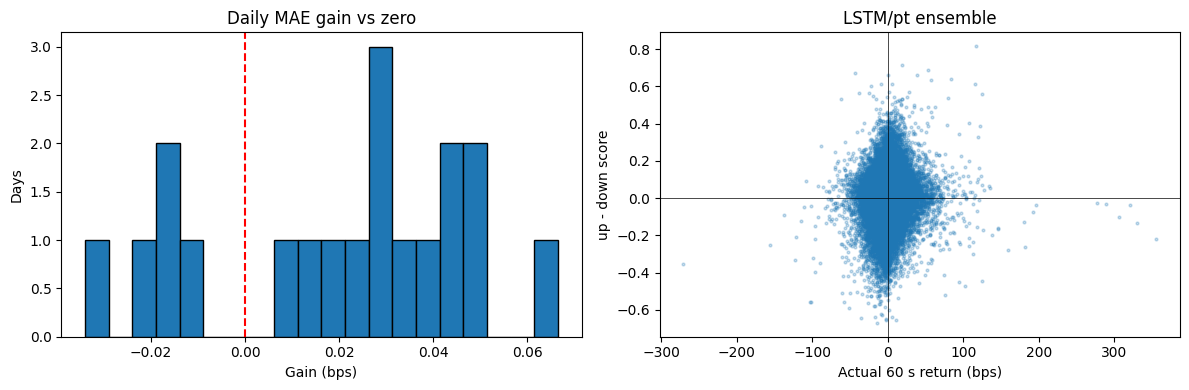

In [11]:
summary_pool = (validation_table.groupby("model", as_index=False)
                 .agg(mean_ic=("pool_ic_reg","mean"),
                      mean_sign_acc=("pool_sign_accuracy_conf","mean"),
                      mean_confident=("pool_confident_share","mean"),
                      mean_mae=("pool_mae_bps","mean"),
                      sd_mae=("pool_mae_bps","std")))
summary_pt = (validation_table.groupby("model", as_index=False)
              .agg(mean_ic=("pt_ic_reg","mean"),
                   mean_sign_acc=("pt_sign_accuracy_conf","mean"),
                   mean_confident=("pt_confident_share","mean"),
                   mean_mae=("pt_mae_bps","mean"),
                   sd_mae=("pt_mae_bps","std")))
print("Pooled fine-tune summary across seeds")
display(summary_pool.round(4).sort_values("mean_ic", ascending=False))
print("\nPer-ticker fine-tune summary across seeds")
display(summary_pt.round(4).sort_values("mean_ic", ascending=False))

# Seed ensemble per architecture + variant
ensemble_rows = []
ensemble_outputs = {}
for arch in MODELS:
    for variant, store in [("pool", val_predictions_pooled), ("pt", val_predictions_pt)]:
        cls_list = [store["cls"][f"{arch}_seed{s}"] for s in SEEDS]
        reg_list = [store["reg"][f"{arch}_seed{s}"] for s in SEEDS]
        cls_mean = np.mean(cls_list, axis=0); reg_mean = np.mean(reg_list, axis=0)
        scored = evaluate_detailed(val_ds.y_bps[PRIMARY_HORIZON_S],
                                    cls_mean, reg_mean, val_ds.stock,
                                    STOCK_STD_MAP, val_quarantine, sessions=val_sessions)
        pooled = scored["pooled"] or {}
        ensemble_rows.append({"model": arch, "variant": variant, **pooled})
        ensemble_outputs[(arch, variant)] = {"cls": cls_mean, "reg": reg_mean, "scored": scored}
ensemble_table = pd.DataFrame(ensemble_rows)
print("\nSEED-ENSEMBLE validation")
display(ensemble_table[["model","variant","n","ic_spearman","ic_t_stat","ic_reg","spearman_cls",
                         "balanced_accuracy","sign_accuracy_conf","confident_share","mae_bps","zero_mae_bps"]]
        .round(4).sort_values("ic_reg", ascending=False))

# Best overall by IC
best_row = ensemble_table.sort_values("ic_reg", ascending=False).iloc[0]
best_key = (best_row["model"], best_row["variant"])
best_out = ensemble_outputs[best_key]
print(f"\nBest ensemble: {best_key[0]} / {best_key[1]}")

# Per-stock table
per_stock_df = pd.DataFrame(best_out["scored"]["per_stock"]).T
per_stock_df.index.name = "ticker"
print(f"\nPer-stock metrics for {best_key[0]}/{best_key[1]} ensemble")
if len(per_stock_df) and "ic_reg" in per_stock_df.columns:
    display(per_stock_df.round(4).sort_values("ic_reg", ascending=False))
else:
    print("per_stock_df is empty (no ticker had >= 50 scored rows)")

# Tick-size check. Large-tick names bounce more between bid and ask prints. If per-stock
# IC rises with tick size, part of the signal is likely residual bounce.
if len(per_stock_df) >= 4 and "ic_spearman" in per_stock_df.columns:
    val_dates = set(val_ds.metadata.session_date.unique())
    mean_spread = frame.loc[frame.session_date.isin(val_dates)].groupby("ticker").tick_bps.mean()
    bounce = per_stock_df[["ic_spearman"]].join(mean_spread.rename("mean_tick_bps"), how="inner")
    rho = bounce.ic_spearman.corr(bounce.mean_tick_bps, method="spearman")
    print(f"\nTick-size check: rank corr(per-stock IC, mean tick size) = {rho:.2f} across {len(bounce)} stocks")
    display(bounce.round(3).sort_values("mean_tick_bps"))

# Daily gain + sign test vs zero
stock_std_vec = np.array([STOCK_STD_MAP[STOCK_VOCAB[s]] for s in val_ds.stock])
pred_bps = best_out["reg"] * stock_std_vec
val_meta = val_ds.metadata.copy()
val_meta["actual_bps"]    = val_ds.y_bps[PRIMARY_HORIZON_S]
val_meta["predicted_bps"] = pred_bps
val_meta["abs_error"]     = np.abs(val_meta.actual_bps - val_meta.predicted_bps)
val_meta["zero_error"]    = np.abs(val_meta.actual_bps)
val_meta["quarantined"]   = val_quarantine
daily = (val_meta.loc[~val_meta.quarantined]
         .groupby("session_date", as_index=False)
         .agg(n=("abs_error","size"), model_mae=("abs_error","mean"),
              zero_mae=("zero_error","mean")))
daily["gain_bps"] = daily.zero_mae - daily.model_mae
pos = int((daily.gain_bps > 0).sum()); tot = len(daily)
from math import comb
if pos >= tot/2:
    p_two = 2 * sum(comb(tot, k) for k in range(pos, tot+1)) * 0.5**tot
else:
    p_two = 2 * sum(comb(tot, k) for k in range(0, pos+1)) * 0.5**tot
print(f"\nDaily gain vs zero: {pos}/{tot} positive days, sign-test p={p_two:.4f}")
display(daily.round({c: 4 for c in daily.select_dtypes("number").columns}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(daily.gain_bps, bins=20, edgecolor="k")
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set(title="Daily MAE gain vs zero", xlabel="Gain (bps)", ylabel="Days")
score = best_out["cls"][:, 2] - best_out["cls"][:, 0]
mask = ~val_quarantine
axes[1].scatter(val_ds.y_bps[PRIMARY_HORIZON_S][mask], score[mask], s=4, alpha=.25)
axes[1].axhline(0, color="k", linewidth=.5); axes[1].axvline(0, color="k", linewidth=.5)
axes[1].set(xlabel="Actual 60 s return (bps)", ylabel="up - down score",
            title=f"{best_key[0]}/{best_key[1]} ensemble")
plt.tight_layout(); plt.show()


## 10. Saved artifacts and checkpoint verification

The run configuration, per-seed and ensemble metrics, per-stock and daily tables, ensemble predictions, training histories and model checkpoints (weights plus input scalers) are written to `RESULTS_DIR`. One checkpoint is reloaded and its predictions are compared against the in-memory model. Raw tick files and the bar cache are stored separately from these lightweight outputs.

In [12]:
run_config = {
    "data_mode": DATA_MODE, "universe_source": UNIVERSE_SOURCE,
    "pretrain_horizons_s": PRETRAIN_HORIZONS_S,
    "primary_horizon_s": PRIMARY_HORIZON_S,
    "horizon_loss_weights": HORIZON_LOSS_WEIGHTS,
    "pretrain_epochs": PRETRAIN_EPOCHS, "finetune_epochs": FINETUNE_EPOCHS,
    "finetune_lr": FINETUNE_LR, "per_ticker_epochs": PER_TICKER_EPOCHS,
    "per_ticker_lr": PER_TICKER_LR, "run_per_ticker": RUN_PER_TICKER,
    "symbols": SYMBOLS, "months": MONTHS, "start": START_DATE, "end": END_DATE,
    "train_end": TRAIN_END, "val_end": VAL_END,
    "grid_s": GRID_SECONDS, "horizon_s": HORIZON_SECONDS,
    "lookback_steps": LOOKBACK_STEPS, "stride_steps": STRIDE_STEPS,
    "feature_set": FEATURE_SET, "features": FEATURE_COLUMNS,
    "models": MODELS, "seeds": SEEDS,
    "loss": LOSS_NAME, "lambda_magnitude": LAMBDA_MAGNITUDE,
    "dead_zone_bps": DEAD_ZONE_BPS, "target_standardize": TARGET_STANDARDIZE,
    "exclude_tickers": EXCLUDE_TICKERS, "quarantine_tickers": QUARANTINE_TICKERS,
    "hidden_dim": HIDDEN_DIM, "embed_dim": EMBED_DIM,
    "lr": LR, "epochs": MAX_EPOCHS, "patience": PATIENCE,
    "stock_vocab": STOCK_VOCAB,
    "stock_std_bps_by_horizon": {str(h): stock_std_all[h] for h in PRETRAIN_HORIZONS_S},
}
with open(RESULTS_DIR/"experiment_config.json","w") as f:
    json.dump(run_config, f, indent=2, default=float)

quality.to_csv(RESULTS_DIR/"bar_quality.csv", index=False)
validation_table.to_csv(RESULTS_DIR/"validation_metrics.csv", index=False)
ensemble_table.to_csv(RESULTS_DIR/"ensemble_metrics.csv", index=False)
per_stock_df.to_csv(RESULTS_DIR/"per_stock_validation.csv")
daily.to_csv(RESULTS_DIR/"daily_validation.csv", index=False)
val_meta.to_csv(RESULTS_DIR/"best_ensemble_predictions.csv", index=False)
for key, fit in trained.items():
    fit["history"].to_csv(RESULTS_DIR/f"history_{key}.csv", index=False)
    pt_state = {t: m.state_dict() for t, m in fit["per_ticker"].items()}
    torch.save({
        "kind": fit["kind"], "seed": fit["seed"],
        "input_dim": len(FEATURE_COLUMNS), "hidden_dim": HIDDEN_DIM,
        "embed_dim": EMBED_DIM, "n_stocks": N_STOCKS,
        "feature_columns": FEATURE_COLUMNS, "stock_vocab": STOCK_VOCAB,
        "pretrain_horizons_s": PRETRAIN_HORIZONS_S,
        "pooled_state": fit["pooled"].state_dict(),
        "per_ticker_state": pt_state,
        "x_mean": fit["x_mean"].tolist(), "x_std": fit["x_std"].tolist(),
    }, RESULTS_DIR/f"model_{key}.pt")

# Sanity: reload one checkpoint and confirm pooled outputs match.
check_name = sorted(trained)[0]
ckpt = torch.load(RESULTS_DIR/f"model_{check_name}.pt", map_location=DEVICE, weights_only=True)
reloaded = build_model(ckpt["kind"], ckpt["input_dim"], ckpt["n_stocks"]).to(DEVICE)
reloaded.load_state_dict(ckpt["pooled_state"], strict=True); reloaded.eval()
reloaded_fit = {
    "pooled": reloaded,
    "per_ticker": {},
    "x_mean": np.asarray(ckpt["x_mean"], dtype=np.float32),
    "x_std":  np.asarray(ckpt["x_std"],  dtype=np.float32),
}
new_cls, new_reg = predict_pooled(reloaded_fit, val_ds)
np.testing.assert_allclose(new_cls, val_predictions_pooled["cls"][check_name], rtol=1e-4, atol=1e-5)
np.testing.assert_allclose(new_reg, val_predictions_pooled["reg"][check_name], rtol=1e-4, atol=1e-5)
print("PASS: reloaded pooled checkpoint matches saved predictions.")
print("Files saved in:", RESULTS_DIR)
print("Best ensemble key:", best_key)


PASS: reloaded pooled checkpoint matches saved predictions.
Files saved in: cn_l2_60s_research/results_60s_multihorizon
Best ensemble key: ('LSTM', 'pt')


## 11. Locked final test

June 2025 is reserved as an untouched test period. All modelling and feature decisions are made on January to May. `RUN_FINAL_TEST` is off by default; the batch run sets it (environment variable `RUN_FINAL_TEST=1`) only with the configuration fixed in advance, so June is evaluated once, on the ensemble selected on May.

In [13]:
if not RUN_FINAL_TEST:
    print("June final test is LOCKED. No test labels or predictions are evaluated here.")
else:
    test_ds = splits["test"]
    arch, variant = best_key
    predict = predict_per_ticker if variant == "pt" else predict_pooled
    preds = [predict(trained[f"{arch}_seed{s}"], test_ds) for s in SEEDS]
    test_cls = np.mean([p[0] for p in preds], axis=0)
    test_reg = np.mean([p[1] for p in preds], axis=0)
    y_test = test_ds.y_bps[PRIMARY_HORIZON_S]
    test_quarantine = np.isin(test_ds.metadata.ticker.to_numpy(), QUARANTINE_TICKERS)
    test_sessions = test_ds.metadata.session_date.to_numpy()
    final = evaluate_detailed(y_test, test_cls, test_reg, test_ds.stock, STOCK_STD_MAP,
                              test_quarantine, sessions=test_sessions)
    zero = evaluate_detailed(y_test, np.tile([0.0, 1.0, 0.0], (len(y_test), 1)),
                             np.zeros(len(y_test)), test_ds.stock, STOCK_STD_MAP,
                             test_quarantine, sessions=test_sessions)
    print(f"FINAL TEST (run once, after model selection is frozen): {arch}/{variant} seed ensemble")
    display(pd.DataFrame([{"model": f"{arch}/{variant} ensemble", **final["pooled"]},
                          {"model": "zero return", **zero["pooled"]}]).round(4))
    display(pd.DataFrame(final["per_stock"]).T.round(4))
    out = test_ds.metadata.copy()
    out["actual_bps"] = y_test
    out["predicted_bps"] = test_reg * np.array([STOCK_STD_MAP[STOCK_VOCAB[s]] for s in test_ds.stock])
    out["p_down"], out["p_flat"], out["p_up"] = test_cls[:, 0], test_cls[:, 1], test_cls[:, 2]
    out.to_csv(RESULTS_DIR/"FINAL_TEST_predictions.csv", index=False)
    print("Saved:", RESULTS_DIR/"FINAL_TEST_predictions.csv")

FINAL TEST (run once, after model selection is frozen): LSTM/pt seed ensemble


,model,n,mae_bps,zero_mae_bps,rmse_bps,ic_reg,ic_spearman,ic_t_stat,ic_sessions,spearman_cls,balanced_accuracy,confident_share,sign_accuracy_conf,actual_std,pred_std
0,LSTM/pt ensemble,105057,7.7794,7.8019,12.3678,0.104,0.1025,25.2155,20,0.1033,0.4407,0.2252,0.5767,12.407,2.03
1,zero return,105057,7.8019,7.8019,12.4072,NaN,NaN,NaN,0,NaN,0.3333,0.0000,NaN,12.407,0.00


,n,mae_bps,zero_mae_bps,rmse_bps,ic_reg,ic_spearman,ic_t_stat,ic_sessions,spearman_cls,balanced_accuracy,confident_share,sign_accuracy_conf,actual_std,pred_std
000099.SZ,2115.0,4.6892,4.7115,7.3757,0.0530,0.0932,3.0707,20.0,0.0706,0.3884,0.1154,0.5697,7.3634,0.9061
000415.SZ,2116.0,11.0279,10.9635,14.8102,0.0292,0.0218,0.6130,20.0,0.0277,0.3490,0.0822,0.4885,14.8045,0.8914
000528.SZ,2119.0,4.8962,4.8734,6.7468,0.0741,0.0616,3.0031,20.0,0.0767,0.3600,0.0920,0.5436,6.7593,0.7863
000766.SZ,2107.0,12.0889,12.1318,19.1129,0.0282,0.0830,4.4434,20.0,0.0855,0.4452,0.2468,0.5712,19.0529,1.4034
001696.SZ,2120.0,5.3986,5.3561,8.3914,0.0875,0.0966,3.0959,20.0,0.0975,0.4327,0.2443,0.5714,8.3674,1.5936
002126.SZ,2117.0,7.1228,7.1051,10.6480,0.0720,0.0724,2.7622,20.0,0.0688,0.4337,0.1856,0.5573,10.6386,1.6253
002130.SZ,2120.0,10.0545,10.0113,15.2547,0.1065,0.1072,4.1680,20.0,0.1018,0.4627,0.4868,0.5630,15.1735,3.6267
002139.SZ,2115.0,5.2710,5.2636,7.1092,0.0801,0.0793,4.3865,20.0,0.0774,0.3752,0.0700,0.5743,7.1219,0.7470
002312.SZ,2120.0,6.1871,6.2715,10.6102,0.1315,0.1282,4.7475,20.0,0.1185,0.3988,0.1811,0.6224,10.6997,1.3308
002400.SZ,2120.0,7.5671,7.6613,12.1590,0.1583,0.1379,4.5867,20.0,0.1344,0.3841,0.1443,0.6209,12.3131,1.8331


Saved: cn_l2_60s_research/results_60s_multihorizon/FINAL_TEST_predictions.csv


## Limitations and extensions

1. **No quotes.** The feed has trades only, so there is no midquote, spread or displayed depth, and the label is a forward VWAP change rather than a midquote change. The tick-size check in section 9 flags residual bounce.
2. **Inferred side in Shenzhen.** The aggressor is inferred from order sequence numbers; Shanghai reports it directly.
3. **Price limits and corporate actions.** The previous close is the last continuous-session trade of the prior day in the sample, not the official closing-auction price, and is not adjusted for dividends or bonus shares. The limit-distance features are clipped to the limit band to bound the effect.
4. **Tradeability.** T+1 settlement and short-sale restrictions mean a down forecast cannot generally be traded by opening a short position; the economic test should be long-only or inventory-based.
5. **Extensions.** The second half of 2025 is available for walk-forward validation, and the full order book (if the sponsor can provide snapshots) would allow the US midquote design to be replicated exactly.